<a href="https://colab.research.google.com/github/dahyeeeya/streamlit-app/blob/main/%EC%8A%A4%EC%BF%A8%EC%A1%B4_%EA%B4%80%EB%A6%AC%EA%B3%B5%EB%B0%B1_%EB%B6%84%EC%84%9D_ipynb%EC%9D%98_%EC%82%AC%EB%B3%B8.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 서울 초등학교 통학환경 관리 공백 분석

## 무엇을 하는 노트북인가

학교 앞 통학 차량을 다루는 두 제도가 학교별로 어떻게 적용되고 있는지 분석합니다.

| 제도 | 역할 | 지정 주체 |
|---|---|---|
| 안심승하차구역 | 5분 정차 허용 구간 지정 | 경찰청 |
| 중점 공회전 제한장소 | 공회전 시 즉시 과태료 | 시장·구청장 |

둘 다 적용되지 않은 학교를 **관리 공백**으로 정의하고, 그 분포가 무엇으로 설명되는지 검증합니다.

## 드라이브에 올릴 파일 (7개)

`내 드라이브`에 **`schoolzone`** 폴더를 만들고 아래를 넣어주세요.

| 파일 | 출처 |
|---|---|
| `전국어린이보호구역표준데이터.csv` | 공공데이터포털 |
| `붙임2_어린이보호구역_통학차량_승하차_구간_선정_결과.pdf` | 서울시교육청 공문 |
| `붙임1_중점_공회전_제한장소_현황.pdf` | 서울시 공고 |
| `불법주정차단속_위치정보(25년10월~12월).csv` | 서울 열린데이터광장 (53MB) |
| `12_25_child.csv` | 도로교통공단 어린이 사고다발지역 |
| `2026년도_학년별_학급별_학생수_초_서울특별시교육청.csv` | 서울시교육청 |
| `2026_세부사업별_세출현황(지출현황).csv` | 서울재정포털 |

**파일명은 아래 1번 셀에서 지정하므로, 실제 이름과 다르면 그 셀만 고치면 됩니다.**

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

!apt-get -qq install -y fonts-nanum > /dev/null
!pip -q install geopandas pdfplumber

import matplotlib.pyplot as plt
import matplotlib.font_manager as fm
fm.fontManager.addfont('/usr/share/fonts/truetype/nanum/NanumGothic.ttf')
plt.rcParams['font.family'] = 'NanumGothic'
plt.rcParams['axes.unicode_minus'] = False

import pandas as pd, numpy as np, re
import geopandas as gpd, pdfplumber
from scipy import stats

PATH = '/content/drive/MyDrive/schoolzone/'

# ▼ 실제 파일명과 다르면 여기만 고치세요
F_보호구역 = '전국어린이보호구역표준데이터.csv'
F_승하차존 = '붙임2_어린이보호구역_통학차량_승하차_구간_선정_결과.pdf'
F_공회전   = '붙임1_중점_공회전_제한장소_현황.pdf'
F_단속     = '불법주정차단속_위치정보(25년10월~12월).csv'
F_사고     = '12_25_child.csv'
F_학생수   = '2026년도_학년별_학급별_학생수_초_서울특별시교육청.csv'
F_예산     = '2026_세부사업별_세출현황(지출현황).csv'

import os
print('폴더 내 파일:')
for f in sorted(os.listdir(PATH)): print(' -', f)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
폴더 내 파일:
 - 12_25_child.csv
 - 2026_세부사업별_세출현황(지출현황).csv
 - 2026년도_학년별_학급별_학생수_초_서울특별시교육청.csv
 - Data_SafeZone_Preprocessing.ipynb
 - 결과_승하차구역_목록.csv
 - 결과_우선순위지수.csv
 - 결과_자치구별_현황.csv
 - 결과_학교별_관리공백.csv
 - 불법주정차단속_위치정보(25년10월~12월).csv
 - 붙임1_중점_공회전_제한장소_현황.pdf
 - 붙임2_어린이보호구역_통학차량_승하차_구간_선정_결과.pdf
 - 서울시_학교_현황.csv
 - 전국어린이보호구역표준데이터.csv


## 1. 기준 데이터 — 서울 초등학교 보호구역

전국 어린이보호구역 표준데이터에서 서울의 초등학교만 추립니다.
좌표, CCTV 설치 대수, 보호구역 도로폭이 함께 들어 있습니다.

In [ ]:
c = pd.read_csv(PATH + F_보호구역, encoding='cp949', dtype=str)
c = c[(c['시설종류'] == '초등학교') &
      (c['소재지도로명주소'].str.startswith('서울', na=False))].copy()
c['자치구'] = c['소재지도로명주소'].str.split().str[1]
c['위도'] = c['위도'].astype(float); c['경도'] = c['경도'].astype(float)
c['도로폭'] = pd.to_numeric(c['보호구역도로폭'], errors='coerce')
c['CCTV'] = pd.to_numeric(c['CCTV설치대수'], errors='coerce')

print('서울 초등학교 보호구역: {}개소 / 자치구 {}개'.format(len(c), c['자치구'].nunique()))
print('도로폭 보유율 {:.0%}, CCTV 보유율 {:.0%}'.format(c['도로폭'].notna().mean(), c['CCTV'].notna().mean()))

서울 초등학교 보호구역: 604개소 / 자치구 25개
도로폭 보유율 38%, CCTV 보유율 85%


## 2. 승하차구역 목록 추출 (PDF → 표)

서울경찰청이 선정한 승하차구역은 76쪽짜리 PDF 표로만 제공됩니다.
`pdfplumber`로 표를 읽어 데이터로 바꿉니다. 이때 **표지판 문구 열도 함께 저장**해 두었다가 4번에서 분석합니다.

In [ ]:
rows = []
경찰서 = None
with pdfplumber.open(PATH + F_승하차존) as pdf:
    for p in pdf.pages:
        txt = p.extract_text() or ''
        m = re.search(r'\d+\.\s*(\S*경찰서)', txt)
        if m: 경찰서 = m.group(1)
        for t in p.extract_tables():
            for r in t:
                if not r or len(r) < 3: continue
                v = [(x or '').replace('\n', ' ').strip() for x in r]
                v = v + [''] * (7 - len(v))               # 열 부족 시 빈칸 채움
                if not re.match(r'^\d+$', v[0]): continue
                길이 = re.search(r'\((\d+)\s*m\)', v[2])
                rows.append(dict(경찰서=경찰서, 연번=int(v[0]), 시설물명=v[1], 정차구간=v[2],
                                 길이m=int(길이.group(1)) if 길이 else np.nan,
                                 표지판종류=v[4], 보조표지판=v[5], 선정사유=v[6]))
z = pd.DataFrame(rows).drop_duplicates(subset=['연번', '시설물명'])
z['시설명'] = z['시설물명'].str.split('(').str[0].str.strip()

def 유형(s):
    for k in ['초등학교', '초교', '유치원', '어린이집', '특수학교']:
        if k in str(s): return k
    return '기타'
z['유형'] = z['시설명'].apply(유형)

print('승하차구역 추출: {}건 / 경찰서 {}개'.format(len(z), z['경찰서'].nunique()))
print(z['유형'].value_counts().to_string())
print('\n정차구간 길이(m): 중앙값 {:.0f} / 최소 {:.0f} / 최대 {:.0f}'.format(
    z['길이m'].median(), z['길이m'].min(), z['길이m'].max()))

승하차구역 추출: 168건 / 경찰서 23개
유형
초등학교    76
유치원     40
어린이집    34
기타      10
초교       8

정차구간 길이(m): 중앙값 12 / 최소 6 / 최대 40


## 3. 중점 공회전 제한장소 추출

서울시가 공고한 지정 현황(39쪽)에서 장소명·분류를 읽어옵니다.
분류가 `교육환경보호구역`인 항목이 학교 주변입니다.

In [ ]:
!apt-get -qq install -y poppler-utils > /dev/null

import subprocess
subprocess.run(['pdftotext', '-layout', PATH + F_공회전, '/content/idle.txt'])
t = open('/content/idle.txt', encoding='utf-8', errors='replace').read()

분류어 = r'(차고지|주차장\(노상\)|주차장\(노외\)|주차장\(부설\)|교육환경보호구역|기타\(도로변\)|터미널|기타)'
rows = []
for l in t.split('\n'):
    m = re.match(r'^\s*(\d{1,4})\s+(\S+구)\s+(.+?)\s{2,}(.+?)\s{2,}' + 분류어 + r'\s*(신규|정보변경)?\s*$', l.replace('\x0c', '').rstrip())
    if m:
        rows.append(dict(연번=int(m.group(1)), 자치구=m.group(2), 장소명=m.group(3).strip(),
                         소재지=m.group(4).strip(), 분류=m.group(5)))
i = pd.DataFrame(rows)
print('중점 공회전 제한장소: {}건'.format(len(i)))
print(i['분류'].value_counts().to_string())

edu = i[i['분류'] == '교육환경보호구역']
print('\n교육환경보호구역 {}곳 / 자치구 {}개'.format(len(edu), edu['자치구'].nunique()))
print('자치구별 지정 수 (하위 5개)')
print(edu.groupby('자치구').size().sort_values().head(5).to_string())

중점 공회전 제한장소: 2332건
분류
교육환경보호구역    1407
주차장(노상)      312
차고지          287
주차장(노외)      145
주차장(부설)      138
기타(도로변)       32
터미널            6
기타             5

교육환경보호구역 1407곳 / 자치구 24개
자치구별 지정 수 (하위 5개)
자치구
종로구      9
중구      27
금천구     32
용산구     35
서대문구    36


### 학교명 정규화

세 데이터의 학교 이름 표기가 모두 다릅니다.

| 출처 | 표기 |
|---|---|
| 보호구역 | 신은초교 |
| 승하차구역 | 신은초등학교 |
| 공회전 제한 | 서울신은초등학교 |

`서울`, `초등학교`, `초교`, 공백·괄호를 제거한 **정규화 키**로 맞춥니다.

In [ ]:
def key(x):
    s = re.sub(r'(서울|병설유치원|초등학교|초교|초등|초)', '', str(x))
    return re.sub(r'[\s()·.]', '', s)

c['키'] = c['대상시설명'].apply(key)
승하차_키 = set(z[z['유형'].isin(['초등학교', '초교'])]['시설명'].apply(key))
공회전_키 = set(edu[edu['장소명'].str.contains('초등학교|초교', na=False)]['장소명'].apply(key))

c['승하차존'] = c['키'].isin(승하차_키)
c['공회전제한'] = c['키'].isin(공회전_키)
c['관리공백'] = (~c['승하차존']) & (~c['공회전제한'])

print('승하차구역 보유: {}개 ({:.1%})'.format(c['승하차존'].sum(), c['승하차존'].mean()))
print('공회전 제한 지정: {}개 ({:.1%})'.format(c['공회전제한'].sum(), c['공회전제한'].mean()))
print('관리 공백: {}개 ({:.1%})'.format(c['관리공백'].sum(), c['관리공백'].mean()))

표 = pd.crosstab(c['공회전제한'], c['승하차존'])
표.index = ['공회전제한 ✕', '공회전제한 ○']; 표.columns = ['승하차존 ✕', '승하차존 ○']
print(); print(표.to_string())

승하차구역 보유: 80개 (13.2%)
공회전 제한 지정: 391개 (64.7%)
관리 공백: 185개 (30.6%)

         승하차존 ✕  승하차존 ○
공회전제한 ✕     185      28
공회전제한 ○     339      52


## 4. 학생 수 결합 — 대상 규모

In [ ]:
s = pd.read_csv(PATH + F_학생수, encoding='utf-8-sig', dtype=str)
s['학생수'] = pd.to_numeric(s['학생수(계)'], errors='coerce')
s['키'] = s['학교명'].apply(key)
c = c.merge(s[['키', '학생수']].drop_duplicates('키'), on='키', how='left')

print('서울 초등학생 총 {:,.0f}명'.format(s['학생수'].sum()))
print('관리 공백 학교 학생 수: {:,.0f}명'.format(c[c['관리공백']]['학생수'].sum()))

서울 초등학생 총 322,736명
관리 공백 학교 학생 수: 85,742명


## 5. [그림 1] 제도 적용 현황과 정차구간 길이

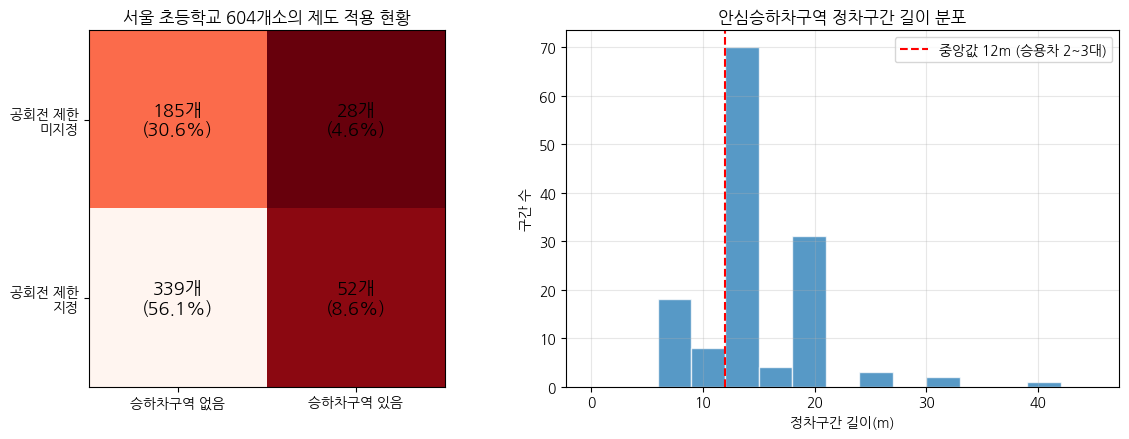

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))

# (좌) 2×2 분류
vals = [[(~c['공회전제한'] & ~c['승하차존']).sum(), (~c['공회전제한'] & c['승하차존']).sum()],
        [(c['공회전제한'] & ~c['승하차존']).sum(), (c['공회전제한'] & c['승하차존']).sum()]]
im = ax[0].imshow(vals, cmap='Reds_r')
for r in range(2):
    for col in range(2):
        ax[0].text(col, r, f'{vals[r][col]}개\n({vals[r][col]/len(c):.1%})',
                   ha='center', va='center', fontsize=13, weight='bold')
ax[0].set_xticks([0, 1]); ax[0].set_xticklabels(['승하차구역 없음', '승하차구역 있음'])
ax[0].set_yticks([0, 1]); ax[0].set_yticklabels(['공회전 제한\n미지정', '공회전 제한\n지정'])
ax[0].set_title('서울 초등학교 {}개소의 제도 적용 현황'.format(len(c)))

# (우) 정차구간 길이
ax[1].hist(z['길이m'].dropna(), bins=range(0, 46, 3), color='tab:blue', alpha=.75, edgecolor='white')
ax[1].axvline(z['길이m'].median(), color='red', ls='--',
              label='중앙값 {:.0f}m (승용차 2~3대)'.format(z['길이m'].median()))
ax[1].set_xlabel('정차구간 길이(m)'); ax[1].set_ylabel('구간 수')
ax[1].set_title('안심승하차구역 정차구간 길이 분포')
ax[1].legend(); ax[1].grid(alpha=.3)
plt.tight_layout(); plt.show()

## 6. [그림 2] 자치구별 관리 공백률

학교 특성이 아니라 자치구에 따라 갈리는지 확인합니다.

 자치구  초등학교  승하차존  공회전제한  관리공백   공백률
 노원구    42     0      0    42 100.0
 은평구    30     1      0    29  96.7
 종로구    12     1      0    11  91.7
 동작구    21     0      2    19  90.5
 용산구    14     3      0    11  78.6
 구로구    26     5      2    20  76.9
 광진구    21     7      0    14  66.7
 중랑구    24    11      0    13  54.2
서대문구    19     0     13     6  31.6
 금천구    18     0     14     4  22.2
 강동구    29     0     23     6  20.7
 강북구    15     2     12     3  20.0
 도봉구    23     3     21     2   8.7
  중구    12     1     11     1   8.3
 성북구    29     0     27     2   6.9
 성동구    21     2     20     1   4.8
 서초구    23     9     22     1   4.3
 강서구    35     5     35     0   0.0
 관악구    22     7     22     0   0.0
 강남구    33     5     33     0   0.0
 마포구    22     7     21     0   0.0
동대문구    20     2     20     0   0.0
영등포구    23     1     23     0   0.0
 송파구    41     0     41     0   0.0
 양천구    29     8     29     0   0.0


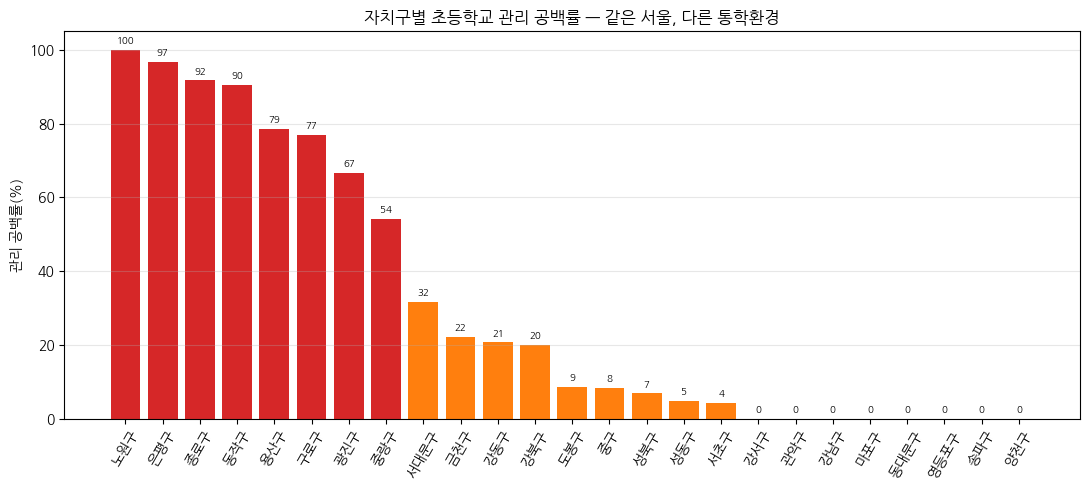

In [ ]:
g = c.groupby('자치구').agg(초등학교=('대상시설명', 'size'), 승하차존=('승하차존', 'sum'),
                          공회전제한=('공회전제한', 'sum'), 관리공백=('관리공백', 'sum')).reset_index()
g['공백률'] = (g['관리공백'] / g['초등학교'] * 100).round(1)
g = g.sort_values('공백률', ascending=False)
print(g.to_string(index=False))

plt.figure(figsize=(11, 5))
색 = ['tab:red' if v >= 50 else ('tab:orange' if v > 0 else 'tab:blue') for v in g['공백률']]
plt.bar(g['자치구'], g['공백률'], color=색)

for i, v in enumerate(g['공백률']):
    plt.text(i, v + 1, f'{v:.0f}', ha='center', va='bottom', fontsize=7)

plt.ylabel('관리 공백률(%)'); plt.xticks(rotation=60)
plt.title('자치구별 초등학교 관리 공백률 — 같은 서울, 다른 통학환경')
plt.grid(axis='y', alpha=.3)
plt.tight_layout(); plt.show()

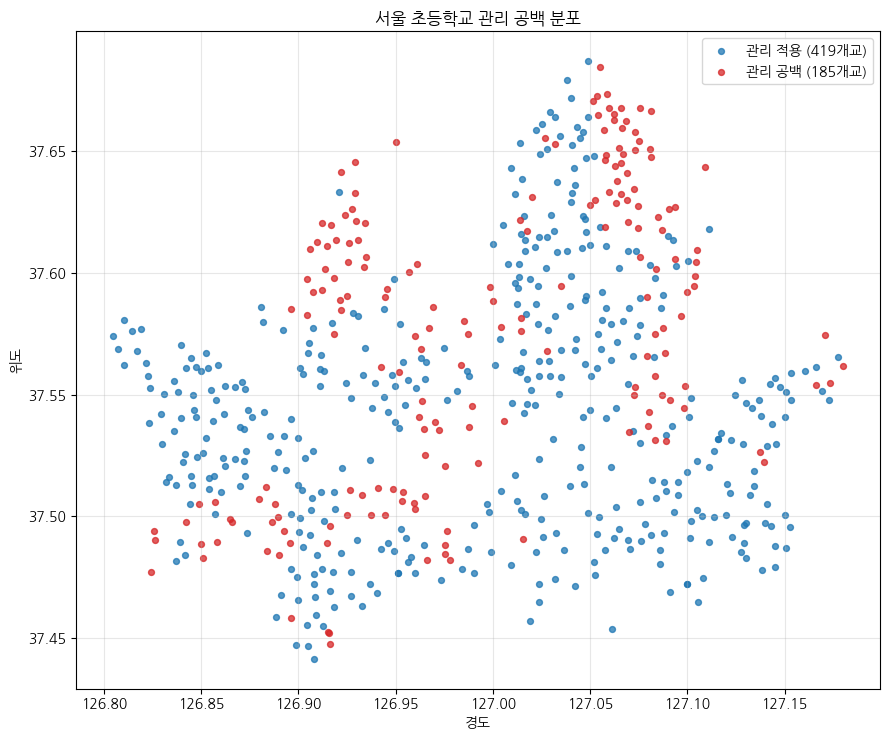

In [ ]:
# 지도: 학교 위치와 관리 공백 여부
plt.figure(figsize=(9, 7.5))
for flag, 색, 라벨 in [(False, 'tab:blue', '관리 적용'), (True, 'tab:red', '관리 공백')]:
    x = c[c['관리공백'] == flag]
    plt.scatter(x['경도'], x['위도'], s=18, alpha=.75, c=색, label=f'{라벨} ({len(x)}개교)')
plt.xlabel('경도'); plt.ylabel('위도')
plt.title('서울 초등학교 관리 공백 분포')
plt.legend(); plt.grid(alpha=.3)
plt.tight_layout(); plt.show()

## 7. 공백은 무엇으로 설명되는가

학교 규모·도로폭·CCTV·사고·예산과의 관계를 차례로 검정합니다.
**차이가 없다는 결과 자체가 분석 결과**입니다. 여건이 아니라 행정적 선택이 결정한다는 뜻이기 때문입니다.

In [ ]:
print('■ 학교 특성 비교 (Mann-Whitney U 검정)')
for v, 이름 in [('학생수', '학생 수'), ('도로폭', '보호구역 도로폭'), ('CCTV', 'CCTV 대수')]:
    a = c[c['관리공백']][v].dropna(); b = c[~c['관리공백']][v].dropna()
    u, p = stats.mannwhitneyu(a, b)
    print('  {:14s}: 공백 {:.1f} (n={}) vs 나머지 {:.1f} (n={}) → p={:.3f}'.format(
        이름, a.median(), len(a), b.median(), len(b), p))

■ 학교 특성 비교 (Mann-Whitney U 검정)
  학생 수          : 공백 419.5 (n=174) vs 나머지 487.0 (n=418) → p=0.068
  보호구역 도로폭      : 공백 10.0 (n=55) vs 나머지 8.0 (n=173) → p=0.247
  CCTV 대수       : 공백 3.0 (n=139) vs 나머지 3.0 (n=374) → p=0.123


In [ ]:
# 어린이 교통사고 다발지역
acc = pd.read_csv(PATH + F_사고, encoding='cp949', dtype=str, low_memory=False)
acc['위도'] = acc['위도'].astype(float); acc['경도'] = acc['경도'].astype(float)
acc['사고건수'] = acc['사고건수'].astype(int)
acc = acc[acc['시도시군구명'].str.startswith('서울', na=False)]
print('서울 어린이 사고다발지역 {}곳 / 사고 {}건'.format(len(acc), acc['사고건수'].sum()))

ga = gpd.GeoDataFrame(acc, geometry=gpd.points_from_xy(acc['경도'], acc['위도']), crs=4326).to_crs(5186)
gc = gpd.GeoDataFrame(c, geometry=gpd.points_from_xy(c['경도'], c['위도']), crs=4326).to_crs(5186)

for R in [300, 500]:
    buf = gc.copy(); buf['geometry'] = buf.geometry.buffer(R)
    j = gpd.sjoin(ga, buf[['대상시설명', 'geometry']], how='inner', predicate='within')
    cnt = j.groupby('대상시설명')['사고건수'].sum().rename(f'사고_{R}')
    c = c.merge(cnt, on='대상시설명', how='left')
    c[f'사고_{R}'] = c[f'사고_{R}'].fillna(0)
    a = c[c['관리공백']][f'사고_{R}']; b = c[~c['관리공백']][f'사고_{R}']
    u, p = stats.mannwhitneyu(a, b)
    print('  반경 {}m 사고건수: 공백 {:.2f} vs 나머지 {:.2f} → p={:.3f}'.format(R, a.mean(), b.mean(), p))

서울 어린이 사고다발지역 213곳 / 사고 729건
  반경 300m 사고건수: 공백 0.77 vs 나머지 0.87 → p=0.532
  반경 500m 사고건수: 공백 1.88 vs 나머지 1.76 → p=0.687


## 8. [그림 3] 예산과 관리 공백

자치구가 집행한 어린이보호구역 개선 예산과 공백률의 관계를 봅니다.
예산이 원인이라면 음의 상관이 나타나야 합니다.

자치구 집행 총액: 4,528,342,360원
공백률 vs 학교당 집행액: 피어슨 r=+0.023 (p=0.913) / 스피어만 r=-0.091 (p=0.664)


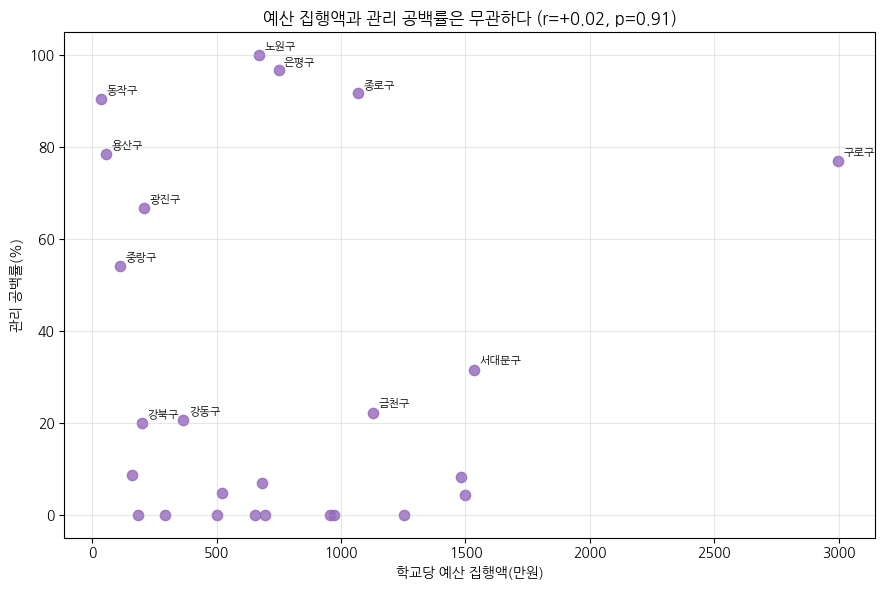

In [ ]:
b = pd.read_csv(PATH + F_예산, encoding='utf-8-sig', dtype=str)
b['지출액'] = pd.to_numeric(b['지출액'].str.replace(',', ''), errors='coerce')
b['자치구'] = b['부서명'].str.extract(r'^(\S+구)')
집행 = b.dropna(subset=['자치구']).groupby('자치구')['지출액'].sum().rename('집행액').reset_index()
print('자치구 집행 총액: {:,.0f}원'.format(집행['집행액'].sum()))

g = g.merge(집행, on='자치구', how='left').fillna({'집행액': 0})
g['학교당집행_만원'] = (g['집행액'] / g['초등학교'] / 10000).round(0)
r = stats.pearsonr(g['공백률'], g['학교당집행_만원'])
s_ = stats.spearmanr(g['공백률'], g['학교당집행_만원'])
print('공백률 vs 학교당 집행액: 피어슨 r={:+.3f} (p={:.3f}) / 스피어만 r={:+.3f} (p={:.3f})'.format(
    r[0], r[1], s_[0], s_[1]))

plt.figure(figsize=(9, 6))
plt.scatter(g['학교당집행_만원'], g['공백률'], s=55, alpha=.8, color='tab:purple')
for _, row in g.iterrows():
    if row['공백률'] >= 10 or row['학교당집행_만원'] > 2000:
        plt.annotate(row['자치구'], (row['학교당집행_만원'], row['공백률']),
                     fontsize=8, xytext=(4, 4), textcoords='offset points')
plt.xlabel('학교당 예산 집행액(만원)'); plt.ylabel('관리 공백률(%)')
plt.title('예산 집행액과 관리 공백률은 무관하다 (r={:+.2f}, p={:.2f})'.format(r[0], r[1]))
plt.grid(alpha=.3); plt.tight_layout(); plt.show()

## 9. [그림 4] 표지판 문구 전수 확인

설치된 승하차구역이 실제로 어떻게 운영되는지 확인합니다.
학교 주변은 중점 공회전 제한장소이므로, 표지판에 공회전 안내가 있는지가 관건입니다.

구간 거리 안내          : 154 / 168 (92%)
공회전·시동 안내         :   0 / 168 (0%)
정차 허용시간(5분)       :   2 / 168 (1%)
선정 사유 기재          :  98 / 168 (58%)


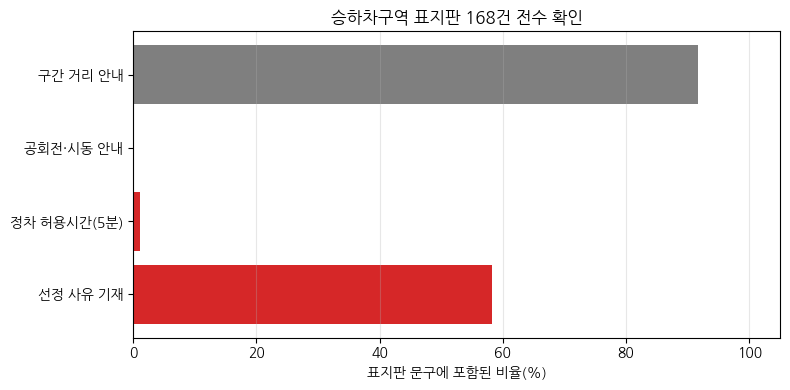

In [ ]:
zt = z[(z['표지판종류'].fillna('').str.strip() != '') | (z['보조표지판'].fillna('').str.strip() != '')]
문구 = (zt['표지판종류'].fillna('') + ' ' + zt['보조표지판'].fillna('') + ' ' + zt['선정사유'].fillna(''))
문구 = (z['표지판종류'].fillna('') + ' ' + z['보조표지판'].fillna('') + ' ' + z['선정사유'].fillna(''))
항목 = {
    '구간 거리 안내': 문구.str.contains('m 까지|m까지|구간시작').sum(),
    '공회전·시동 안내': 문구.str.contains('공회전|시동|엔진').sum(),
    '정차 허용시간(5분)': 문구.str.contains('5분|3분').sum(),
    '선정 사유 기재': (zt['선정사유'].fillna('').str.strip() != '').sum(),
}
전체 = len(zt)
for k, v in 항목.items():
    print('{:18s}: {:3d} / {} ({:.0%})'.format(k, v, 전체, v / 전체))

plt.figure(figsize=(8, 4))
plt.barh(list(항목.keys())[::-1], [v / 전체 * 100 for v in 항목.values()][::-1],
         color=['tab:gray', 'tab:orange', 'tab:red', 'tab:red'][::-1])
plt.xlabel('표지판 문구에 포함된 비율(%)'); plt.xlim(0, 105)
plt.title('승하차구역 표지판 {}건 전수 확인'.format(전체))
plt.grid(axis='x', alpha=.3); plt.tight_layout(); plt.show()

## 10. 우선순위 지수 — 어디부터 설치해야 하는가

앞선 검정에서 현행 설치는 학교 규모·사고·예산·특수학급 어느 것과도 관련이 없었다.
기준이 없다는 뜻이다. 그렇다면 기준을 만들어 본다.

공개 데이터로 구성 가능한 5개 지표를 표준화해 합산하고,
현재 설치 현황과 비교한다.

In [ ]:
from sklearn.preprocessing import StandardScaler

# 특수학급 학생 수 결합
sp = pd.read_csv(PATH + '서울시_학교_현황.csv', encoding='cp949', dtype=str, low_memory=False)
sp = sp[(sp['학교급코드'] == '02') & (sp['공시연도'] == sp['공시연도'].max())].copy()
sp['특수학생'] = sp['학생수계'].str.extract(r'\((\d+)\)').astype(float)
sp['키'] = sp['학교명'].apply(key)
c = c.merge(sp[['키', '특수학생']].drop_duplicates('키'), on='키', how='left')

# 보호구역 내 불법주정차 단속 건수 (반경 300m)
dn = pd.read_csv(PATH + F_단속, encoding='utf-8-sig', low_memory=False)
dn['경도'] = pd.to_numeric(dn['경도'], errors='coerce')
dn['위도'] = pd.to_numeric(dn['위도'], errors='coerce')
dn = dn.dropna(subset=['경도', '위도'])
gd = gpd.GeoDataFrame(dn, geometry=gpd.points_from_xy(dn['경도'], dn['위도']), crs=4326).to_crs(5186)
gc = gpd.GeoDataFrame(c, geometry=gpd.points_from_xy(c['경도'], c['위도']), crs=4326).to_crs(5186)
buf = gc.copy(); buf['geometry'] = buf.geometry.buffer(300)
j = gpd.sjoin(gd, buf[['대상시설명', 'geometry']], how='inner', predicate='within')
c = c.merge(j.groupby('대상시설명').size().rename('단속'), on='대상시설명', how='left')

c['공회전공백'] = (~c['공회전제한']).astype(int)
c[['특수학생', '사고_300', '단속', '학생수']] = c[['특수학생', '사고_300', '단속', '학생수']].fillna(0)

지표 = ['특수학생', '학생수', '사고_300', '단속', '공회전공백']
c['우선순위점수'] = StandardScaler().fit_transform(c[지표]).sum(axis=1)
c['순위'] = c['우선순위점수'].rank(ascending=False).astype(int)

print('투입 지표:', 지표)
print('동일 가중 합산, 표준화 후 산출')

투입 지표: ['특수학생', '학생수', '사고_300', '단속', '공회전공백']
동일 가중 합산, 표준화 후 산출


In [ ]:
대상학생 = c[c['관리공백']]['학생수'].sum()
공회전계수 = 48          # kg CO2/년 (하루 5분 공회전 저감 시, 서울시)

print('관리 공백 학교 학생 수: {:,.0f}명'.format(대상학생))
print()
for 비율, 출처 in [(0.029, '서울 승용차'), (0.101, '서울 차량 전체'), (0.42, '서귀포 상한')]:
    대수 = 대상학생 * 비율
    톤 = 대수 * 공회전계수 / 1000
    print('차량 통학 {:5.1%} ({:10s}) → 대상 {:,.0f}명 · 연 {:,.0f}톤 CO2'.format(비율, 출처, 대수, 톤))
print()
print('※ 서울 값은 12세 이상 기준(인구주택총조사 2020)으로 하한이며,')
print('   차량 1대당 1명, 하루 5분 공회전을 가정한 추정치입니다.')

관리 공백 학교 학생 수: 85,742명

차량 통학  2.9% (서울 승용차    ) → 대상 2,487명 · 연 119톤 CO2
차량 통학 10.1% (서울 차량 전체  ) → 대상 8,660명 · 연 416톤 CO2
차량 통학 42.0% (서귀포 상한    ) → 대상 36,012명 · 연 1,729톤 CO2

※ 서울 값은 12세 이상 기준(인구주택총조사 2020)으로 하한이며,
   차량 1대당 1명, 하루 5분 공회전을 가정한 추정치입니다.


In [ ]:
설치수 = int(c['승하차존'].sum())
top = c.nlargest(설치수, '우선순위점수')
일치 = int(top['승하차존'].sum())

print('■ 우선순위 상위 {}개교 vs 실제 설치 {}개교'.format(설치수, 설치수))
print('   겹치는 학교: {}개 ({:.1%})'.format(일치, 일치 / 설치수))
print()
print('설치 학교 평균 순위: {:.0f}위 / 미설치 평균: {:.0f}위'.format(
    c[c['승하차존']]['순위'].mean(), c[~c['승하차존']]['순위'].mean()))
u, p = stats.mannwhitneyu(c[c['승하차존']]['우선순위점수'], c[~c['승하차존']]['우선순위점수'])
print('설치 여부별 점수 차이: p={:.3f}'.format(p))
print()
print('■ 우선순위 상위 15개교 (미설치 우선)')
print(top[~top['승하차존']].head(15)[
    ['대상시설명', '자치구', '특수학생', '학생수', '사고_300', '단속', '공회전제한']
].to_string(index=False))

■ 우선순위 상위 80개교 vs 실제 설치 80개교
   겹치는 학교: 11개 (13.8%)

설치 학교 평균 순위: 284위 / 미설치 평균: 305위
설치 여부별 점수 차이: p=0.297

■ 우선순위 상위 15개교 (미설치 우선)
  대상시설명  자치구  특수학생    학생수  사고_300     단속  공회전제한
   갈현초등  은평구  12.0  659.0    14.0  751.0  False
   장평초교 동대문구  13.0  969.0     6.0 1111.0   True
신상도초등학교  동작구  14.0 1169.0     5.0  284.0  False
가재울초등학교 서대문구  15.0 1491.0     3.0  190.0  False
 신정초등학교  강서구  19.0  953.0     8.0  221.0   True
 도곡초등학교  강남구   8.0  786.0    14.0  130.0   True
 월정초등학교  강서구  14.0  700.0    11.0  160.0   True
 개봉초등학교  구로구   8.0  807.0     9.0   97.0  False
 을지초등학교  노원구   0.0 1365.0     9.0  102.0  False
 매동초등학교  종로구   6.0  178.0     3.0 1758.0  False
   은명초등  은평구  13.0  940.0     4.0  329.0  False
 중계초등학교  노원구   6.0  685.0     3.0 1105.0  False
 화곡초등학교  강서구  14.0  445.0    11.0  188.0   True
 항동초등학교  구로구  18.0 1405.0     0.0   30.0  False
 화일초등학교  강서구  12.0  565.0    11.0  152.0   True


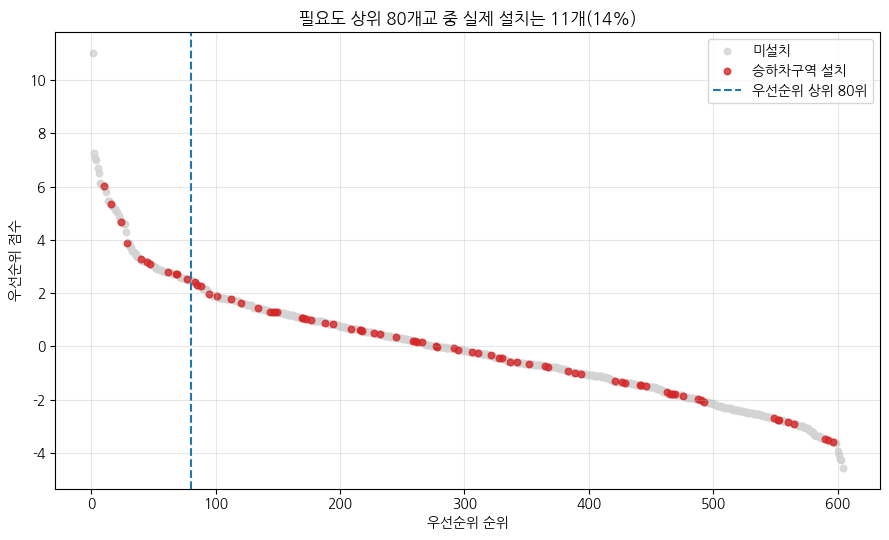

In [ ]:
plt.figure(figsize=(9, 5.5))
for flag, 색, 라벨 in [(False, 'lightgray', '미설치'), (True, 'tab:red', '승하차구역 설치')]:
    x = c[c['승하차존'] == flag]
    plt.scatter(x['순위'], x['우선순위점수'], s=22, alpha=.8, c=색, label=라벨)
plt.axvline(설치수, ls='--', color='tab:blue', label=f'우선순위 상위 {설치수}위')
plt.xlabel('우선순위 순위'); plt.ylabel('우선순위 점수')
plt.title('필요도 상위 {}개교 중 실제 설치는 {}개({:.0%})'.format(설치수, 일치, 일치/설치수))
plt.legend(); plt.grid(alpha=.3); plt.tight_layout(); plt.show()

■ 현행 배분 vs 무작위 배분
  전체 604개교 중 80개 설치
  우선순위 상위 80개와 실제 겹침: 11개
  무작위로 80개를 뽑았을 때 기대 겹침: 10.6개
  P(겹침 ≥ 11) = 0.501
  무작위 10,000회 시뮬레이션: 평균 10.6, 95% 구간 5~16

→ 실제 겹침 11개는 무작위 기대값 10.6개와 통계적으로 구별되지 않는다.


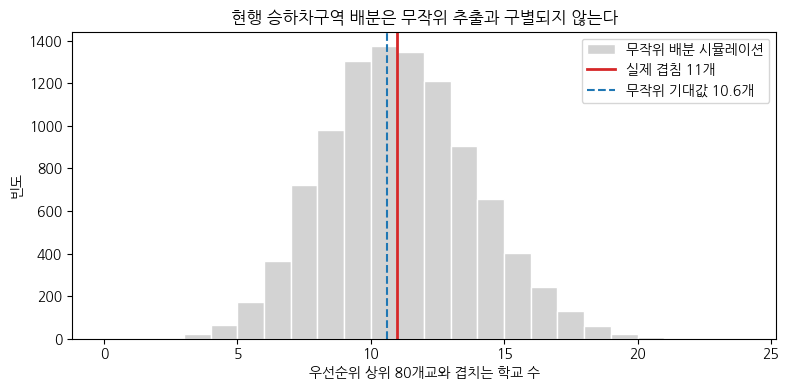

In [ ]:
from scipy import stats

n = len(c)
k = int(c['승하차존'].sum())
기대 = k * k / n
실제 = int(c.nlargest(k, '우선순위점수')['승하차존'].sum())

print('■ 현행 배분 vs 무작위 배분')
print('  전체 {}개교 중 {}개 설치'.format(n, k))
print('  우선순위 상위 {}개와 실제 겹침: {}개'.format(k, 실제))
print('  무작위로 {}개를 뽑았을 때 기대 겹침: {:.1f}개'.format(k, 기대))

# 초기하분포 검정: 실제 겹침이 우연보다 많은가
p = stats.hypergeom.sf(실제 - 1, n, k, k)
print('  P(겹침 ≥ {}) = {:.3f}'.format(실제, p))

# 시뮬레이션으로 재확인
rng = np.random.default_rng(42)
sims = np.array([len(set(rng.choice(n, k, replace=False)) & set(range(k))) for _ in range(10000)])
print('  무작위 10,000회 시뮬레이션: 평균 {:.1f}, 95% 구간 {:.0f}~{:.0f}'.format(
    sims.mean(), np.percentile(sims, 2.5), np.percentile(sims, 97.5)))
print()
print('→ 실제 겹침 {}개는 무작위 기대값 {:.1f}개와 통계적으로 구별되지 않는다.'.format(실제, 기대))

plt.figure(figsize=(8, 4))
plt.hist(sims, bins=range(0, 25), color='lightgray', edgecolor='white', label='무작위 배분 시뮬레이션')
plt.axvline(실제, color='tab:red', lw=2, label='실제 겹침 {}개'.format(실제))
plt.axvline(기대, color='tab:blue', ls='--', label='무작위 기대값 {:.1f}개'.format(기대))
plt.xlabel('우선순위 상위 {}개교와 겹치는 학교 수'.format(k)); plt.ylabel('빈도')
plt.title('현행 승하차구역 배분은 무작위 추출과 구별되지 않는다')
plt.legend(); plt.tight_layout(); plt.show()

In [ ]:
시나리오 = {
    '동일 가중(기본)':      {'특수학생':1, '학생수':1, '사고_300':1, '단속':1, '공회전공백':1},
    '특수학급 2배':         {'특수학생':2, '학생수':1, '사고_300':1, '단속':1, '공회전공백':1},
    '사고 2배':             {'특수학생':1, '학생수':1, '사고_300':2, '단속':1, '공회전공백':1},
    '단속 제외':            {'특수학생':1, '학생수':1, '사고_300':1, '단속':0, '공회전공백':1},
    '규모만(학생+특수)':    {'특수학생':1, '학생수':1, '사고_300':0, '단속':0, '공회전공백':0},
    '안전만(사고+단속)':    {'특수학생':0, '학생수':0, '사고_300':1, '단속':1, '공회전공백':0},
}

Z = pd.DataFrame(StandardScaler().fit_transform(c[지표]), columns=지표, index=c.index)
결과 = []
for 이름, w in 시나리오.items():
    점수 = sum(Z[col] * w[col] for col in 지표)
    상위 = c.assign(점수=점수).nlargest(k, '점수')
    결과.append({'시나리오': 이름, '상위 80 중 설치': int(상위['승하차존'].sum()),
                 '비율': '{:.1%}'.format(상위['승하차존'].sum() / k)})
결과 = pd.DataFrame(결과)
print('■ 가중치를 바꿔도 결론은 같은가 (무작위 기대값 {:.1f}개)'.format(기대))
print(결과.to_string(index=False))

■ 가중치를 바꿔도 결론은 같은가 (무작위 기대값 10.6개)
      시나리오  상위 80 중 설치    비율
 동일 가중(기본)          11 13.8%
   특수학급 2배          11 13.8%
     사고 2배          11 13.8%
     단속 제외           9 11.2%
규모만(학생+특수)          14 17.5%
안전만(사고+단속)          11 13.8%


## 11. 효과 추정

공식 통계에 초등학생 통학수단 조사가 없어, 선행 조사값의 **범위**를 적용합니다.
단일 수치가 아니라 범위로 제시하고 가정을 명시하는 것이 중요합니다.

## 12. 결과 저장

In [ ]:
c.to_csv(PATH + '결과_학교별_관리공백.csv', index=False, encoding='utf-8-sig')
g.to_csv(PATH + '결과_자치구별_현황.csv', index=False, encoding='utf-8-sig')
z.to_csv(PATH + '결과_승하차구역_목록.csv', index=False, encoding='utf-8-sig')

c[['대상시설명', '자치구', '순위', '우선순위점수', '특수학생', '학생수',
   '사고_300', '단속', '공회전제한', '승하차존']].sort_values('순위').to_csv(
    PATH + '결과_우선순위지수.csv', index=False, encoding='utf-8-sig')

print('저장 완료')

저장 완료


## 보고서에 쓸 핵심 수치 정리

| 항목 | 값 |
|---|---|
| 서울 초등학교(보호구역 지정) | 604개소 |
| 안심승하차구역 보유 | 80개 (13.2%) |
| 중점 공회전 제한장소 지정 | 391개 (64.7%) |
| **관리 공백** | **185개 (30.6%), 학생 85,742명** |
| 정차구간 길이 중앙값 | 12m (승용차 2~3대) |
| 표지판 공회전 안내 | **0건 / 145건** |
| 자치구 공백률 | 노원 100% ~ 8개 구 0% |
| 학교 특성과의 관계 | 학생 수 p=0.068, 도로폭 p=0.247, CCTV p=0.123 |
| 어린이 사고와의 관계 | p=0.53(300m), p=0.69(500m) |
| 예산과의 관계 | r=+0.10, p=0.64 |

**해석 시 주의**

- "차이가 없다"는 결과는 제도의 실패가 아니라, 현행 제도가 규모·운영 설계 면에서 작동하지 않고 있음을 시사합니다
- 사고 감소나 위반 감소 효과를 주장해서는 안 됩니다. 본 분석에서 확인되지 않았습니다
- 탄소 추정치는 가정에 기반하므로 반드시 범위와 가정을 함께 제시하세요